<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/dataset_kontrol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys, platform, os
import numpy, pandas, scipy, sklearn, matplotlib, seaborn

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("scipy       :", scipy.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", seaborn.__version__)
print("Platform    :", platform.platform())
print("Jumlah CPU  :", os.cpu_count())

Python      : 3.13.16
scikit-learn: 1.6.1
numpy       : 2.1.3
pandas      : 2.2.3
scipy       : 1.16.3
matplotlib  : 3.10.0
seaborn     : 0.13.2
Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
Jumlah CPU  : 2


In [ ]:
import time, warnings, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.spatial.distance import cdist
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, pairwise_distances)
warnings.filterwarnings('ignore')

N_SAMPLES   = 500       # dari template
BLOBS_STD   = 1.2       # dari template
MOONS_NOISE = 0.1       # pilihan kelompok
RANDOM_STATE = 42
MIN_SAMPLES = 4         # min_samples DBSCAN & HDBSCAN (data 2D)
MCS_FRAKSI  = 0.02      # min_cluster_size HDBSCAN = fraksi x n (sama untuk 3 metrik)
N_ULANG_WAKTU = 3       # waktu = rata-rata beberapa kali run
CHUNK_SIZE = 400
METRIK = ['Euclidean', 'Manhattan', 'Cosine']

DATASET = {
    'Blobs': (make_blobs(n_samples=N_SAMPLES, centers=4, cluster_std=BLOBS_STD, random_state=RANDOM_STATE), 4),
    'Moons': (make_moons(n_samples=N_SAMPLES, noise=MOONS_NOISE, random_state=RANDOM_STATE), 2),
}

In [ ]:
class KMeansEuclidean:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='euclidean')

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]
        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)
        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)
            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.mean(cluster_pts, axis=0)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels
            if shift < self.tol:
                break
        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists ** 2))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self


class KMeansManhattan:
    """K-Means dengan jarak Manhattan (L1). Centroid diupdate pakai median per dimensi."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='manhattan', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]
        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)
        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)
            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.median(cluster_pts, axis=0)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels
            if shift < self.tol:
                break
        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self


class KMeansCosine:
    """K-Means dengan jarak Cosine. Centroid = rata-rata vektor yang dinormalisasi lagi ke bola satuan."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='cosine', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]
        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        centroids = np.array(centroids)
        norms = np.linalg.norm(centroids, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        return centroids / norms

    def fit(self, X):
        start_time = time.perf_counter()
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        X_calc = X / norms
        self.centroids = self._init_centroids(X_calc)
        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X_calc, self.centroids)
            labels = np.argmin(dists, axis=1)
            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X_calc[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X_calc[rng.randint(len(X_calc))]
                else:
                    mean_vec = np.mean(cluster_pts, axis=0)
                    norm = np.linalg.norm(mean_vec)
                    new_centroids[k] = mean_vec / (norm if norm > 0 else 1.0)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels
            if shift < self.tol:
                break
        final_dists = self._compute_distance(X_calc, self.centroids)
        assigned_dists = final_dists[np.arange(len(X_calc)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

In [ ]:
def _blok_jarak(A, B, metric, B_sq=None):
    """Matriks jarak A x B. Euclidean dikembalikan sebagai jarak KUADRAT (tanpa sqrt)."""
    if metric == 'euclidean':
        d = A @ B.T
        d *= -2.0
        d += (A * A).sum(axis=1)[:, None]
        d += (B_sq if B_sq is not None else (B * B).sum(axis=1))[None, :]
        np.maximum(d, 0.0, out=d)
        return d
    if metric == 'cosine':          # data sudah L2-normalized -> jarak cosine = 1 - dot product
        d = A @ B.T
        np.subtract(1.0, d, out=d)
        return d
    return pairwise_distances(A, B, metric='manhattan', n_jobs=-1)


def _ambang(eps, metric):
    return eps * eps if metric == 'euclidean' else eps


def kdistance(X, metric, k, chunk_size=CHUNK_SIZE):
    """Jarak ke tetangga ke-k (titik itu sendiri dihitung sebagai tetangga ke-1)."""
    n = len(X)
    out = np.empty(n)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    for s in range(0, n, chunk_size):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        out[s:s + chunk_size] = np.partition(d, k - 1, axis=1)[:, k - 1]
    return np.sqrt(out) if metric == 'euclidean' else out


def hitung_tetangga(X, metric, eps_list, chunk_size=CHUNK_SIZE):
    """Jumlah tetangga (termasuk diri sendiri) untuk semua nilai eps."""
    n = len(X)
    thr = [_ambang(e, metric) for e in eps_list]
    counts = np.zeros((len(eps_list), n), dtype=np.int32)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    for s in range(0, n, chunk_size):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        for i, t in enumerate(thr):
            counts[i, s:s + chunk_size] = (d <= t).sum(axis=1)
    return counts


class DBSCANManual:
    """DBSCAN manual tim (hemat memori). Satu-satunya perubahan dari kelas di notebook PBL:
    metrik ('euclidean'/'manhattan'/'cosine') menjadi parameter, bukan variabel global METRIC."""
    def __init__(self, eps=0.5, min_pts=5, metric='euclidean', chunk_size=CHUNK_SIZE):
        self.eps = eps
        self.min_pts = min_pts
        self.chunk_size = chunk_size
        self.metric = metric
        self.labels_ = None
        self.core_sample_mask_ = None
        self.n_clusters_ = 0
        self.n_noise_ = 0
        self.execution_time_ = 0.0

    def fit(self, X, counts=None):
        start = time.perf_counter()
        n = X.shape[0]
        if counts is None:
            counts = hitung_tetangga(X, self.metric, [self.eps], self.chunk_size)[0]
        is_core = counts >= self.min_pts
        thr = _ambang(self.eps, self.metric)
        labels = np.full(n, -1, dtype=np.int32)
        cluster_id = 0
        for p in np.where(is_core)[0]:
            if labels[p] != -1:
                continue
            labels[p] = cluster_id
            frontier = np.array([p])
            while len(frontier) > 0:
                cand = np.where(labels == -1)[0]
                if len(cand) == 0:
                    break
                Xc = X[cand]
                Bc_sq = (Xc * Xc).sum(axis=1) if self.metric == 'euclidean' else None
                hit = np.zeros(len(cand), dtype=bool)
                for s in range(0, len(frontier), self.chunk_size):
                    f = frontier[s:s + self.chunk_size]
                    d = _blok_jarak(X[f], Xc, self.metric, Bc_sq)
                    hit |= (d <= thr).any(axis=0)
                baru = cand[hit]
                labels[baru] = cluster_id
                frontier = baru[is_core[baru]]
            cluster_id += 1
        self.labels_ = labels.astype(int)
        self.core_sample_mask_ = is_core
        self.n_clusters_ = cluster_id
        self.n_noise_ = int(np.sum(labels == -1))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

In [ ]:
def siapkan(X, metrik):
    Xs = StandardScaler().fit_transform(X)
    return Normalizer(norm='l2').fit_transform(Xs) if metrik == 'Cosine' else Xs

def eps_siku(X, metrik, k=MIN_SAMPLES):
    """eps dari 'siku' k-distance plot (titik terjauh dari garis lurus awal-akhir kurva)."""
    kd = np.sort(kdistance(X, metrik.lower(), k))
    x = np.linspace(0, 1, len(kd)); y = (kd - kd.min()) / (kd.max() - kd.min() + 1e-12)
    return float(kd[np.argmax(x - y)])

def kmedians_acuan(X, k, rs=RANDOM_STATE, n_init=10, max_iter=100):
    """Pembanding K-Medians (inisialisasi acak, 10 kali) - bukan kode tim."""
    best_lab, best_cost = None, np.inf
    for t in range(n_init):
        rng = np.random.RandomState(rs + t)
        C = X[rng.choice(len(X), k, replace=False)]
        for _ in range(max_iter):
            lab = cdist(X, C, 'cityblock').argmin(1)
            C_new = np.array([np.median(X[lab == j], axis=0) if (lab == j).any() else C[j] for j in range(k)])
            if np.allclose(C_new, C): break
            C = C_new
        D = cdist(X, C, 'cityblock'); lab = D.argmin(1)
        cost = D[np.arange(len(X)), lab].sum()
        if cost < best_cost: best_lab, best_cost = lab, cost
    return best_lab

def jalankan_tim(algo, metrik, X, k_benar, eps=None):
    """Kode TIM untuk K-Means & DBSCAN; HDBSCAN memakai sklearn (sama dengan PBL)."""
    if algo == 'K-Means':
        kelas = {'Euclidean': KMeansEuclidean, 'Manhattan': KMeansManhattan, 'Cosine': KMeansCosine}[metrik]
        return kelas(n_clusters=k_benar, random_state=RANDOM_STATE).fit(X).labels_, f'k={k_benar}'
    if algo == 'DBSCAN':
        return DBSCANManual(eps=eps, min_pts=MIN_SAMPLES, metric=metrik.lower()).fit(X).labels_, \
               f'eps={eps:.4f}, min_samples={MIN_SAMPLES}'
    mcs = max(2, int(round(MCS_FRAKSI * len(X))))
    m = {'Euclidean': 'euclidean', 'Manhattan': 'manhattan', 'Cosine': 'euclidean'}[metrik]  # cosine = euclid pada data L2-normal
    return HDBSCAN(min_cluster_size=mcs, min_samples=MIN_SAMPLES, metric=m).fit_predict(X), \
           f'min_cluster_size={mcs}, min_samples={MIN_SAMPLES}'

def jalankan_acuan(algo, metrik, X, k_benar, eps=None):
    """Implementasi pembanding (sklearn / K-Medians acuan). None = tidak ada pembanding terpisah (HDBSCAN)."""
    if algo == 'K-Means':
        if metrik == 'Manhattan':
            return kmedians_acuan(X, k_benar)
        return KMeans(k_benar, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    if algo == 'DBSCAN':
        return DBSCAN(eps=eps, min_samples=MIN_SAMPLES, metric=metrik.lower(), algorithm='brute').fit_predict(X)
    return None

def evaluasi(X, y, lab, metrik):
    mk = lab != -1
    n_cl = len(set(lab[mk]))
    r = {'k / jumlah klaster': n_cl, '% noise': round((~mk).mean() * 100, 2)}
    ada = n_cl >= 2 and mk.sum() > n_cl
    r['Silhouette'] = round(silhouette_score(X[mk], lab[mk], metric=metrik.lower()), 4) if ada else np.nan
    r['DBI']        = round(davies_bouldin_score(X[mk], lab[mk]), 4) if ada else np.nan
    r['CH']         = round(calinski_harabasz_score(X[mk], lab[mk]), 2) if ada else np.nan
    r['ARI (non-noise)'] = round(adjusted_rand_score(y[mk], lab[mk]), 4) if mk.sum() > 1 else np.nan
    r['NMI (non-noise)'] = round(normalized_mutual_info_score(y[mk], lab[mk]), 4) if mk.sum() > 1 else np.nan
    r['ARI (semua titik)'] = round(adjusted_rand_score(y, lab), 4)   # noise dianggap satu label (-1)
    r['NMI (semua titik)'] = round(normalized_mutual_info_score(y, lab), 4)
    return r

In [ ]:
hasil, semua_label = {}, {}
for nama, ((X_raw, y), k_benar) in DATASET.items():
    rows = []
    for algo in ['K-Means', 'DBSCAN', 'HDBSCAN']:
        for metrik in METRIK:
            X = siapkan(X_raw, metrik)
            eps = eps_siku(X, metrik) if algo == 'DBSCAN' else None
            waktu = []
            for _ in range(N_ULANG_WAKTU):
                t0 = time.perf_counter(); lab, par = jalankan_tim(algo, metrik, X, k_benar, eps)
                waktu.append((time.perf_counter() - t0) * 1000)
            lab_acuan = jalankan_acuan(algo, metrik, X, k_benar, eps)
            ari_acuan = round(adjusted_rand_score(lab_acuan, lab), 4) if lab_acuan is not None else np.nan
            semua_label[(nama, algo, metrik)] = (X, lab)
            rows.append({'Algoritma': algo, 'Metrik': metrik, 'Parameter': par,
                         **evaluasi(X, y, lab, metrik),
                         'ARI vs pembanding': ari_acuan, 'Waktu (ms)': round(np.mean(waktu), 2)})
    hasil[nama] = pd.DataFrame(rows)
    print(f'\n===== DATASET KONTROL: {nama} (n={N_SAMPLES}, k benar={k_benar}) =====')
    print(hasil[nama].to_string(index=False))

with pd.ExcelWriter('hasil_dataset_kontrol.xlsx') as w:
    for nama, df in hasil.items():
        df.to_excel(w, sheet_name=nama, index=False)


===== DATASET KONTROL: Blobs (n=500, k benar=4) =====
Algoritma    Metrik                          Parameter  k / jumlah klaster  % noise  Silhouette    DBI      CH  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)  ARI vs pembanding  Waktu (ms)
  K-Means Euclidean                                k=4                   4      0.0      0.7557 0.3397 3882.31           1.0000           1.0000             1.0000             1.0000                1.0        5.91
  K-Means Manhattan                                k=4                   4      0.0      0.7477 0.3397 3882.31           1.0000           1.0000             1.0000             1.0000                1.0       94.82
  K-Means    Cosine                                k=4                   4      0.0      0.9534 0.2300 6382.41           1.0000           1.0000             1.0000             1.0000                1.0       93.11
   DBSCAN Euclidean          eps=0.1054, min_samples=4                   7      9.0      

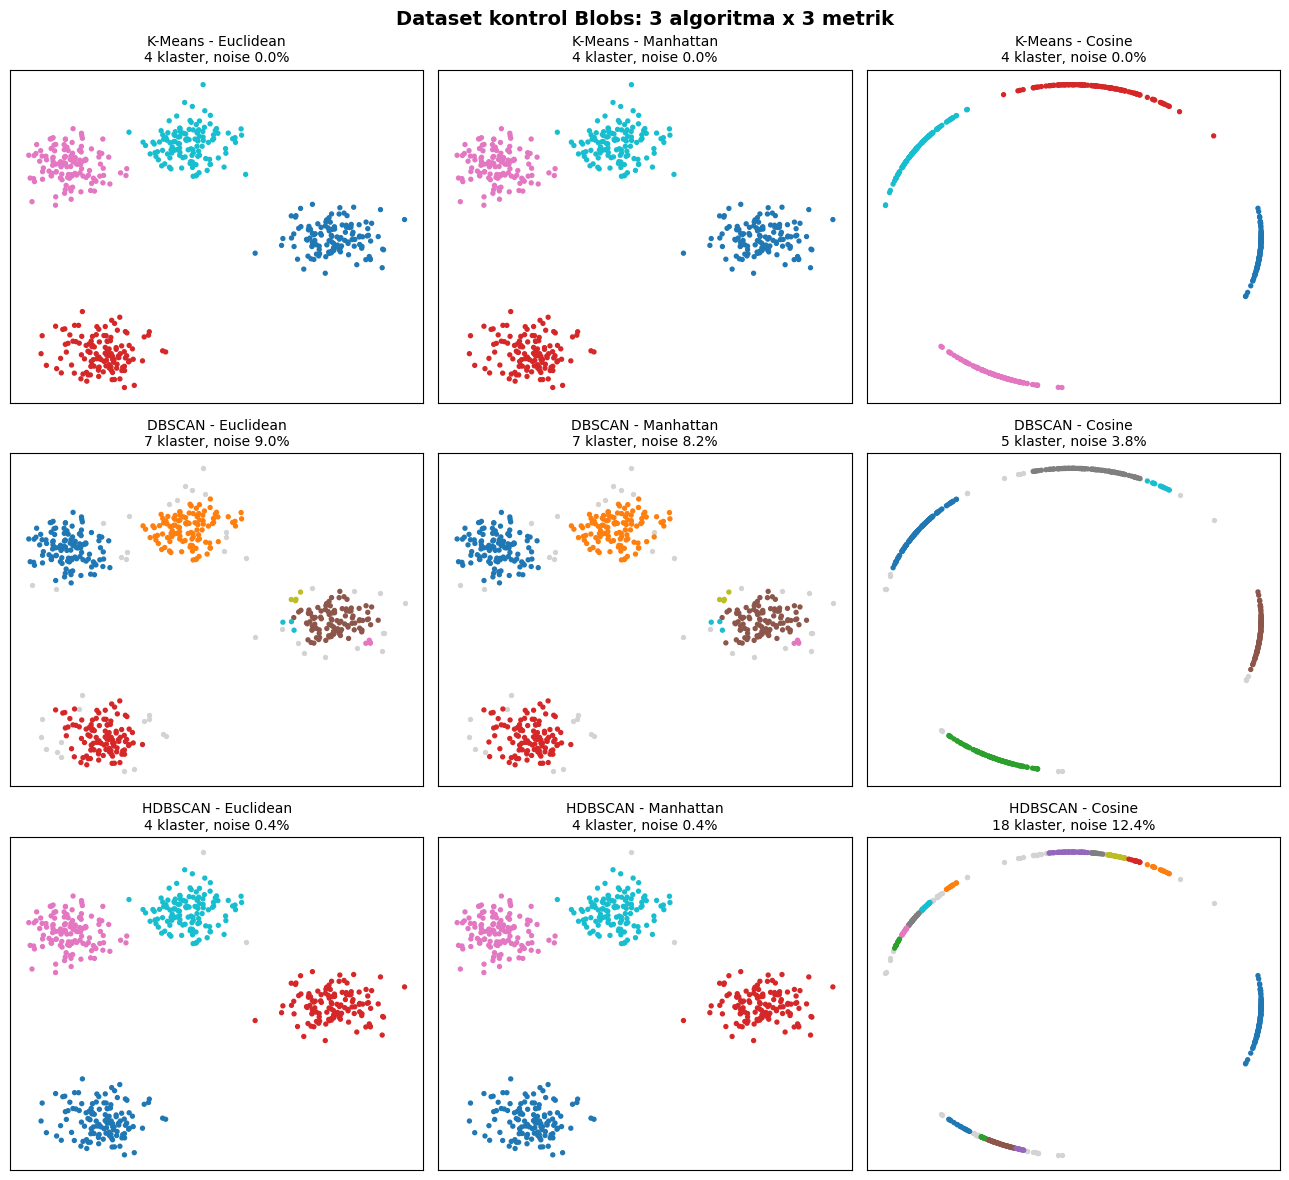

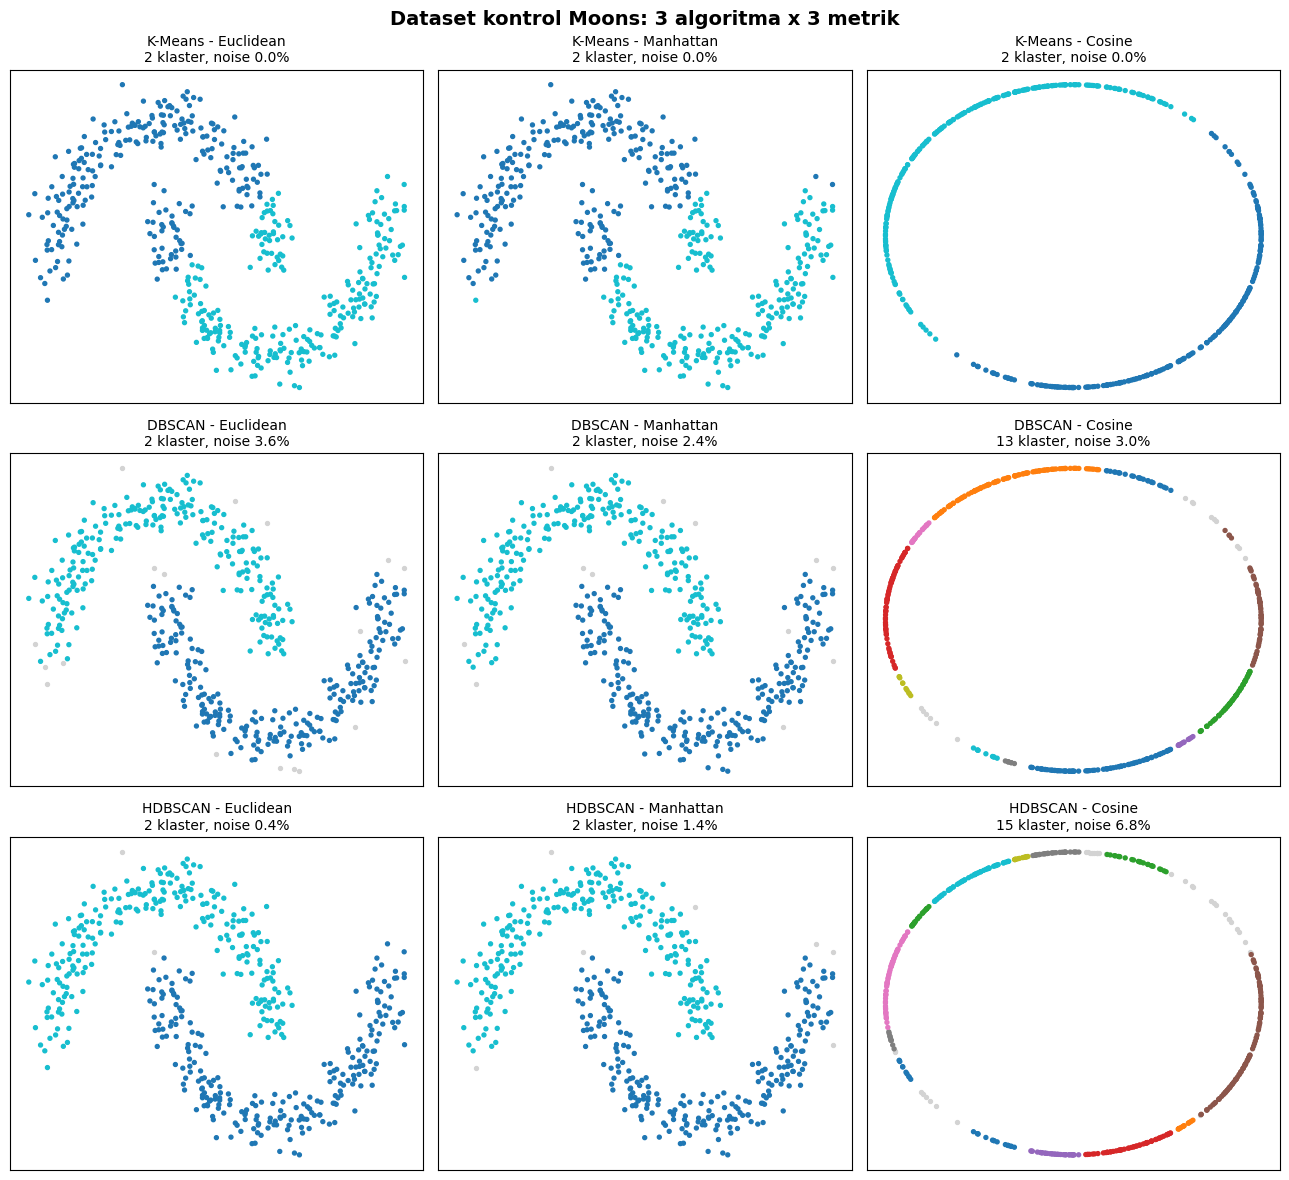

In [ ]:
for nama in DATASET:
    fig, axes = plt.subplots(3, 3, figsize=(13, 12))
    for i, algo in enumerate(['K-Means', 'DBSCAN', 'HDBSCAN']):
        for j, metrik in enumerate(METRIK):
            X, lab = semua_label[(nama, algo, metrik)]
            ax = axes[i, j]
            ax.scatter(X[lab == -1, 0], X[lab == -1, 1], c='lightgray', s=8, label='noise')
            ax.scatter(X[lab != -1, 0], X[lab != -1, 1], c=lab[lab != -1], cmap='tab10', s=8)
            r = hasil[nama].query('Algoritma == @algo and Metrik == @metrik').iloc[0]
            ax.set_title(f'{algo} - {metrik}\n{r["k / jumlah klaster"]} klaster, noise {r["% noise"]}%', fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(f'Dataset kontrol {nama}: 3 algoritma x 3 metrik', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.savefig(f'grid_kontrol_{nama.lower()}.png', dpi=200); plt.show()